# Feature Engineering — REFIT (Niveau 1 : signatures journalières intra-foyer)

## Construction des 7 features journalières pour les 20 foyers REFIT

Ce notebook applique **exactement la même fonction** de feature engineering que celle validée
sur le foyer UCI (module `src/features.py`, fonction `compute_daily_features`), à chacun des
20 foyers REFIT. Aucune adaptation du calcul n'est nécessaire : le rééchantillonnage à 1 minute
effectué au Notebook 01 garantit que chaque journée est représentée par ~1440 points, exactement
comme pour le foyer UCI.

**Rappel des 7 features finales (identiques au TFC) :**

| Feature | Dimension capturée |
|---|---|
| `mean_load` | Niveau de consommation |
| `load_cv` | Stabilité (dispersion relative) |
| `load_factor` | Forme de charge |
| `day_night_ratio` | Comportement jour/nuit |
| `max_load` | Intensité (pic) |
| `num_peaks` | Complexité du profil |
| `is_weekend` | Contexte temporel |

**Objectifs :**
1. Charger les séries nettoyées (Notebook 01)
2. Construire les signatures journalières pour chaque foyer
3. Contrôle de cohérence (distributions, corrélations)
4. Sauvegarder le dataset consolidé `level1_features_raw.csv`

AUTEUR : ENANGA DANIEL CHRISTIAN


## Étape 0 : Imports

In [1]:
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
matplotlib.rcParams['figure.dpi'] = 120

BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.insert(0, os.path.join(BASE_DIR, "src"))

from features import compute_daily_features, build_daily_features_for_house, FEATURES_FINAL

PROCESSED_DIR = os.path.join(BASE_DIR, "data", "processed", "refit")
IMAGES_DIR = os.path.join(BASE_DIR, "images", "FE_REFIT")
os.makedirs(IMAGES_DIR, exist_ok=True)

print("Bibliothèques chargées. FEATURES_FINAL :", FEATURES_FINAL)


Bibliothèques chargées. FEATURES_FINAL : ['mean_load', 'load_cv', 'load_factor', 'day_night_ratio', 'max_load', 'num_peaks', 'is_weekend']


## Étape 1 : Chargement des séries nettoyées (Notebook 01)

In [2]:
clean_files = sorted(
    f for f in os.listdir(PROCESSED_DIR) if f.startswith("house_") and f.endswith("_clean.csv")
)
print(f"{len(clean_files)} foyers nettoyés trouvés dans {PROCESSED_DIR}")

house_series = {}
for fname in clean_files:
    house_id = fname.replace("house_", "").replace("_clean.csv", "")
    df = pd.read_csv(os.path.join(PROCESSED_DIR, fname), index_col=0, parse_dates=True)
    house_series[house_id] = df["power_kw"]
    print(f"  Foyer {house_id} : {len(df):,} points, {df.index.min()} -> {df.index.max()}")

if not house_series:
    print("\n[ATTENTION] Aucun foyer chargé -- exécutez d'abord 01_EDA_REFIT.ipynb avec les données REFIT en place.")


20 foyers nettoyés trouvés dans c:\Users\Christian Enanga\Dossier-du-TFC\TFC-electricity-clustering\paper\refit_project\data\processed\refit
  Foyer 10 : 845,257 points, 2013-11-20 11:31:00 -> 2015-06-30 11:07:00
  Foyer 11 : 564,697 points, 2014-06-03 11:36:00 -> 2015-06-30 15:12:00
  Foyer 12 : 702,199 points, 2014-03-07 10:52:00 -> 2015-07-08 02:10:00
  Foyer 13 : 717,881 points, 2014-01-17 22:26:00 -> 2015-05-31 11:06:00
  Foyer 15 : 817,007 points, 2013-12-17 17:24:00 -> 2015-07-08 02:10:00
  Foyer 16 : 782,833 points, 2014-01-10 10:58:00 -> 2015-07-08 02:10:00
  Foyer 17 : 676,710 points, 2014-03-06 16:23:00 -> 2015-06-19 14:52:00
  Foyer 18 : 635,328 points, 2014-03-07 10:33:00 -> 2015-05-22 15:20:00
  Foyer 19 : 677,470 points, 2014-03-06 16:23:00 -> 2015-06-20 03:32:00
  Foyer 1 : 920,091 points, 2013-10-09 13:06:00 -> 2015-07-10 11:56:00
  Foyer 20 : 662,864 points, 2014-03-20 12:01:00 -> 2015-06-23 19:44:00
  Foyer 21 : 705,337 points, 2014-03-07 16:20:00 -> 2015-07-10 11:56

## Étape 2 : Construction des signatures journalières (7 features) — 20 foyers

Chaque journée devient une observation, exactement selon l'**Hypothèse de représentativité
journalière** validée dans le TFC (une journée = une unité comportementale exploitable).

In [3]:
features_by_house = []

print("=" * 70)
print("CONSTRUCTION DES SIGNATURES JOURNALIÈRES — 20 FOYERS REFIT")
print("=" * 70)

for house_id, series in house_series.items():
    df_feat = build_daily_features_for_house(series, house_id=f"REFIT_{house_id}")
    features_by_house.append(df_feat)
    print(f"  Foyer REFIT_{house_id} : {df_feat.shape[0]} jours exploitables (sur {series.index.normalize().nunique()} jours calendaires)")

if features_by_house:
    df_level1_raw = pd.concat(features_by_house, ignore_index=True)
else:
    df_level1_raw = pd.DataFrame(columns=["house_id", "date"] + FEATURES_FINAL)

print(f"\n=== Dataset Niveau 1 construit : {df_level1_raw.shape[0]} jours x {df_level1_raw.shape[1]} colonnes ===")
df_level1_raw.head()


CONSTRUCTION DES SIGNATURES JOURNALIÈRES — 20 FOYERS REFIT
  Foyer REFIT_10 : 491 jours exploitables (sur 588 jours calendaires)
  Foyer REFIT_11 : 331 jours exploitables (sur 393 jours calendaires)
  Foyer REFIT_12 : 438 jours exploitables (sur 489 jours calendaires)
  Foyer REFIT_13 : 296 jours exploitables (sur 500 jours calendaires)
  Foyer REFIT_15 : 471 jours exploitables (sur 569 jours calendaires)
  Foyer REFIT_16 : 429 jours exploitables (sur 545 jours calendaires)
  Foyer REFIT_17 : 409 jours exploitables (sur 471 jours calendaires)
  Foyer REFIT_18 : 341 jours exploitables (sur 442 jours calendaires)
  Foyer REFIT_19 : 421 jours exploitables (sur 472 jours calendaires)
  Foyer REFIT_1 : 502 jours exploitables (sur 640 jours calendaires)
  Foyer REFIT_20 : 421 jours exploitables (sur 461 jours calendaires)
  Foyer REFIT_21 : 320 jours exploitables (sur 491 jours calendaires)
  Foyer REFIT_2 : 425 jours exploitables (sur 619 jours calendaires)
  Foyer REFIT_3 : 395 jours explo

,house_id,date,mean_load,load_cv,load_factor,day_night_ratio,max_load,num_peaks,is_weekend
0,REFIT_10,2013-11-21,0.729254,1.234386,0.106443,9.239445,6.8511,5,0
1,REFIT_10,2013-11-23,0.582246,0.880250,0.140697,6.154780,4.1383,4,1
2,REFIT_10,2013-11-24,0.970928,1.017835,0.211218,12.262320,4.5968,4,1
3,REFIT_10,2013-11-25,0.858264,0.995831,0.164747,8.491496,5.2096,5,0
4,REFIT_10,2013-11-26,0.721426,0.996434,0.137690,7.319328,5.2395,5,0


## Étape 3 : Contrôle de cohérence — distributions et corrélations

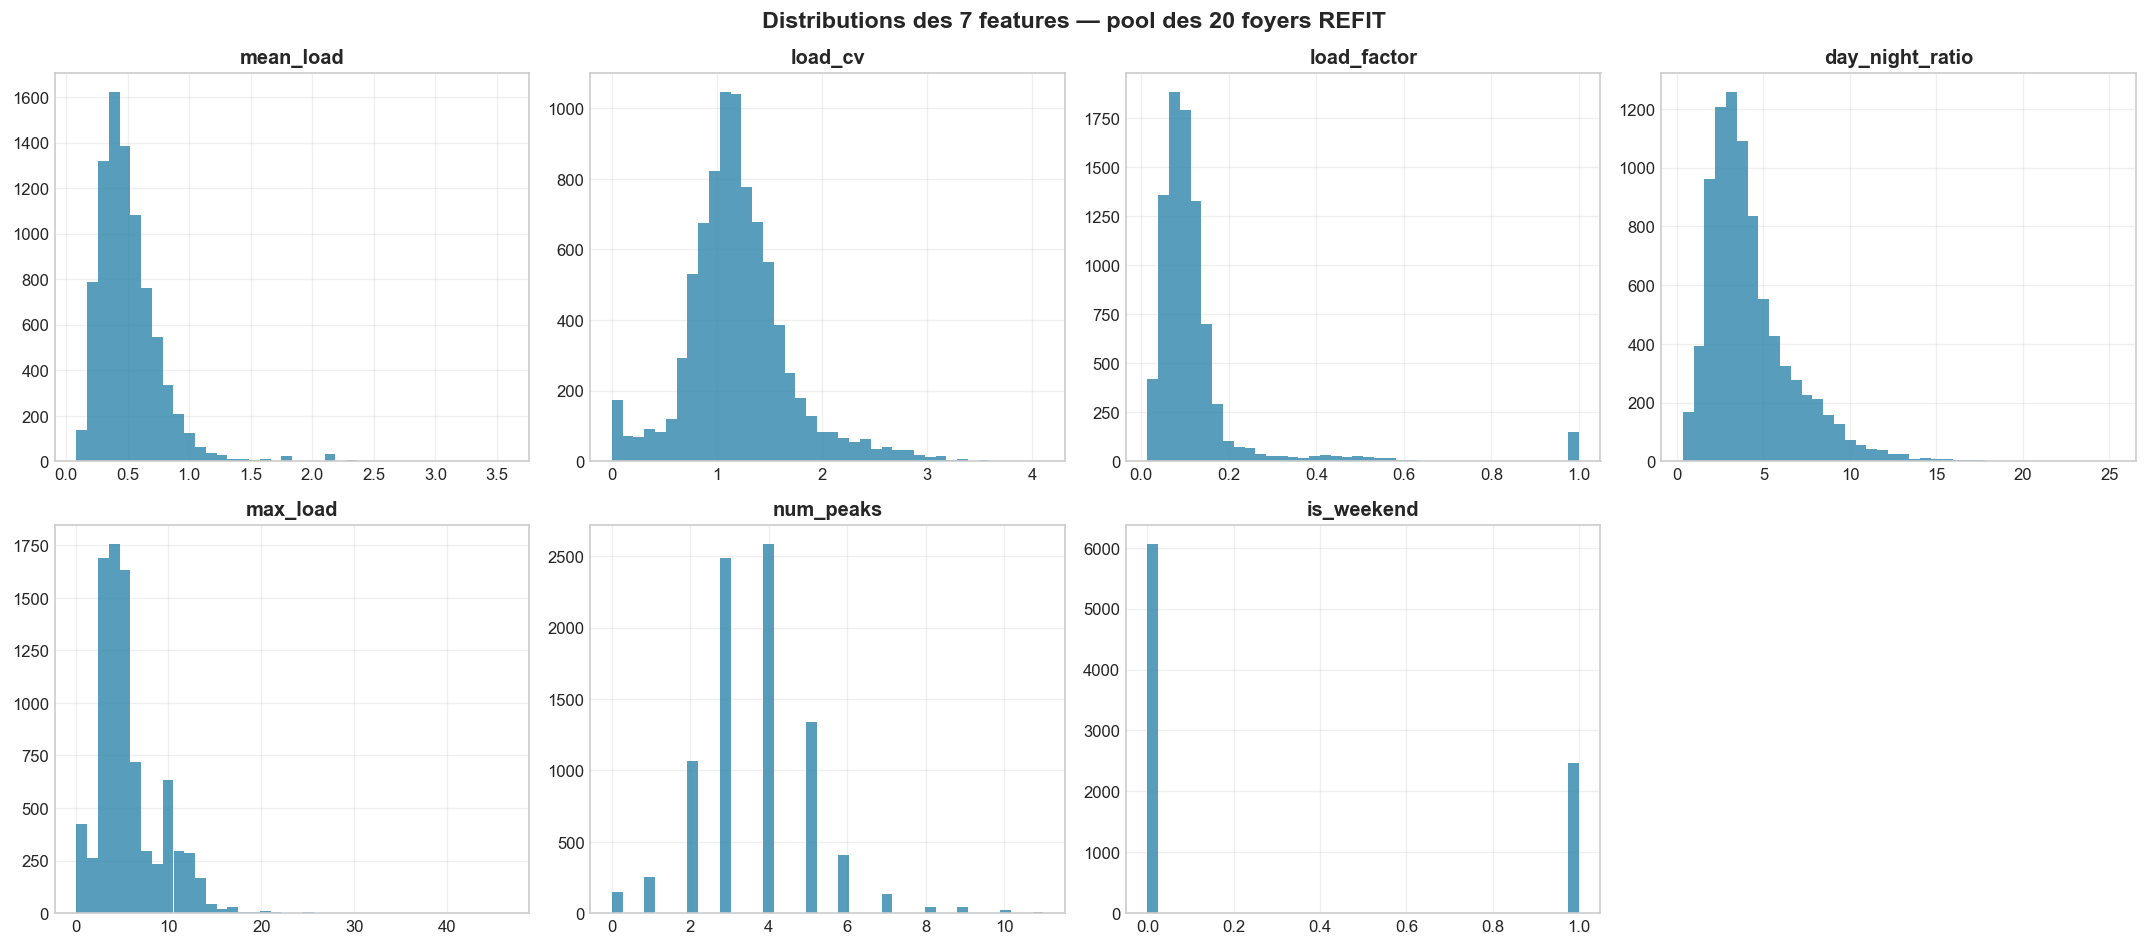


=== Statistiques descriptives (pool des 20 foyers) ===
       mean_load   load_cv  load_factor  day_night_ratio  max_load  num_peaks  \
count   8530.000  8530.000     8530.000         8530.000  8530.000   8530.000   
mean       0.506     1.200        0.127            4.236     5.676      3.663   
std        0.256     0.493        0.142            2.478     3.394      1.429   
min        0.084     0.000        0.014            0.342     0.084      0.000   
25%        0.341     0.929        0.068            2.560     3.460      3.000   
50%        0.458     1.156        0.095            3.603     4.807      4.000   
75%        0.616     1.428        0.129            5.228     6.868      4.000   
max        3.589     4.107        1.000           25.290    46.554     11.000   

       is_weekend  
count    8530.000  
mean        0.289  
std         0.453  
min         0.000  
25%         0.000  
50%         0.000  
75%         1.000  
max         1.000  


In [ ]:
if not df_level1_raw.empty:
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for ax, feat in zip(axes.flatten(), FEATURES_FINAL):
        ax.hist(df_level1_raw[feat].dropna(), bins=40, color="#2E86AB", alpha=0.8)
        ax.set_title(feat, fontweight="bold")
        ax.grid(True, alpha=0.3)
    axes.flatten()[-1].axis("off")
    plt.suptitle("Distributions des 7 features — pool des 20 foyers REFIT", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(IMAGES_DIR, "01_distributions_features_refit.png"), dpi=300, bbox_inches="tight")
    plt.show()

    print("\n=== Statistiques descriptives (pool des 20 foyers) ===")
    print(df_level1_raw[FEATURES_FINAL].describe().round(3))


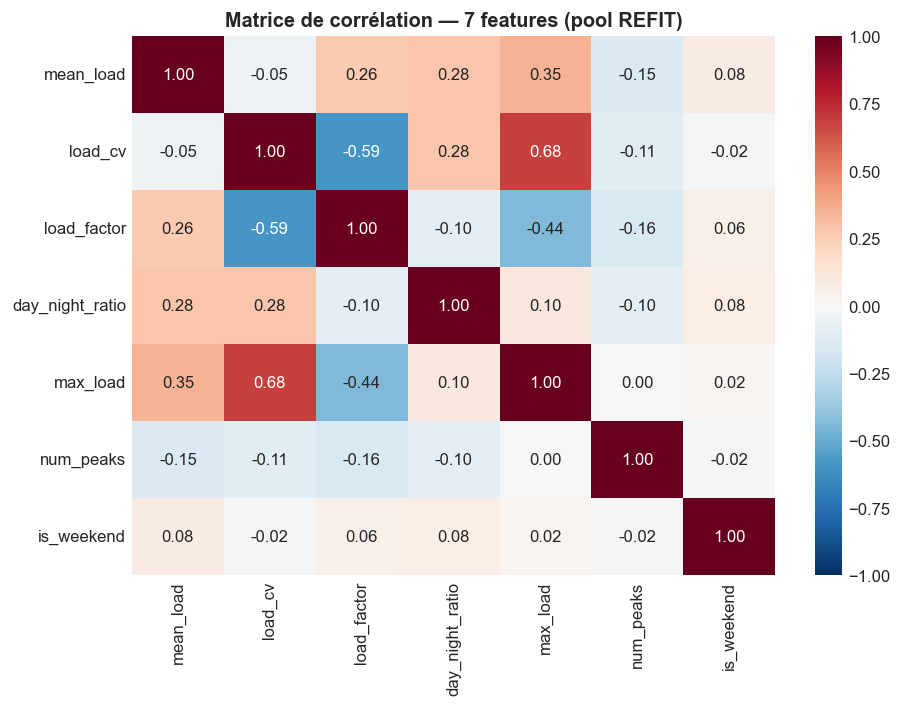

Note : la sélection des 7 features a déjà été validée sur le foyer UCI (TFC original).
Cette vérification confirme seulement l'absence de redondance nouvelle spécifique à REFIT.


In [ ]:
if not df_level1_raw.empty:
    corr = df_level1_raw[FEATURES_FINAL].corr()
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title("Matrice de corrélation — 7 features (pool REFIT)", fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(IMAGES_DIR, "02_correlation_features_refit.png"), dpi=300, bbox_inches="tight")
    plt.show()

    print("Note : la sélection des 7 features a déjà été validée sur le foyer UCI (TFC original).")
    print("Cette vérification confirme seulement l'absence de redondance nouvelle spécifique à REFIT.")


## Étape 4 : Nombre de jours exploitables par foyer

Table de référence pour les notebooks suivants (Niveau 1 et Niveau 2).

In [6]:
if not df_level1_raw.empty:
    days_per_house = df_level1_raw.groupby("house_id").size().rename("n_days").reset_index()
    days_per_house = days_per_house.sort_values("n_days", ascending=False)
    print(days_per_house.to_string(index=False))

    LOW_DAYS_THRESHOLD = 30  # en dessous, le clustering intra-foyer (Niveau 1) devient peu fiable
    low_days = days_per_house[days_per_house["n_days"] < LOW_DAYS_THRESHOLD]
    if not low_days.empty:
        print(f"\n[ATTENTION] Foyers avec moins de {LOW_DAYS_THRESHOLD} jours exploitables "
              f"(clustering intra-foyer à interpréter avec prudence) :")
        print(low_days.to_string(index=False))


house_id  n_days
 REFIT_1     502
 REFIT_4     500
REFIT_10     491
 REFIT_8     485
REFIT_15     471
 REFIT_9     468
 REFIT_6     467
 REFIT_7     464
 REFIT_5     456
REFIT_12     438
REFIT_16     429
 REFIT_2     425
REFIT_20     421
REFIT_19     421
REFIT_17     409
 REFIT_3     395
REFIT_18     341
REFIT_11     331
REFIT_21     320
REFIT_13     296


## Étape 5 : Sauvegarde

In [7]:
out_path = os.path.join(PROCESSED_DIR, "level1_features_raw.csv")
df_level1_raw.to_csv(out_path, index=False)
print(f"Dataset Niveau 1 (signatures journalières, non standardisées) sauvegardé : {out_path}")
print("Note : la standardisation (StandardScaler) est faite PAR FOYER dans le Notebook 03,")
print("       et non ici, car chaque foyer est clusterisé indépendamment (Niveau 1).")


Dataset Niveau 1 (signatures journalières, non standardisées) sauvegardé : c:\Users\Christian Enanga\Dossier-du-TFC\TFC-electricity-clustering\paper\refit_project\data\processed\refit\level1_features_raw.csv
Note : la standardisation (StandardScaler) est faite PAR FOYER dans le Notebook 03,
       et non ici, car chaque foyer est clusterisé indépendamment (Niveau 1).


## Résumé final

**Fichier produit :** `data/processed/refit/level1_features_raw.csv`
(colonnes : `house_id`, `date`, `mean_load`, `load_cv`, `load_factor`, `day_night_ratio`,
`max_load`, `num_peaks`, `is_weekend`)

**Étape suivante :** Notebook `03_Clustering_Level1_Intra_Foyer.ipynb` — réplication du pipeline
de clustering (Cycle 1 + Cycle 2) sur chacun des 20 foyers, en comparaison avec le foyer UCI.
